# Level 1 · Task 2 — Customer Segmentation Analysis
**Track:** Data Analytics · Level 1  
**Goal:** Use K-Means clustering to split a company's customers into distinct groups that can be targeted with different marketing strategies.

**Dataset:** *Customer Segmentation* (`Train.csv`): 8,068 customers of an automobile company, with demographics, work profile and a `Spending_Score`.



In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Load Data & Inspect Structure

In [10]:
df = pd.read_csv("Train.csv")
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum(), "| Unique customer IDs:", df["ID"].nunique())
print("\nMissing values per column:")
print(df.isnull().sum())
df.head()

Shape: (8068, 11)
Duplicate rows: 0 | Unique customer IDs: 8068

Missing values per column:
ID                   0
Gender               0
Ever_Married       140
Age                  0
Graduated           78
Profession         124
Work_Experience    829
Spending_Score       0
Family_Size        335
Var_1               76
Segmentation         0
dtype: int64


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


### Observations
- **8,068 customers, 11 columns**, with no duplicate rows and unique IDs.
- Six columns have missing values. The largest is `Work_Experience` (829 missing, 10%), then `Family_Size` (335), `Ever_Married` (140), `Profession` (124), `Graduated` (78) and `Var_1` (76).
- The dataset also comes with `Segmentation` (A/B/C/D), the company's own labels. I **do not use it for clustering** (K-Means is unsupervised), but I compare against it in Section 10.
- I only use `Train.csv`. `Test.csv` has no labels, and **2,332 of its 2,627 IDs also appear in `Train.csv`**, so combining the files would count the same customers twice. `sample_submission.csv` is only a competition template and is not needed.

## 2. Handle Missing Values and Inconsistent Data

In [11]:
data = df.copy()

# --- Inconsistent data: work experience that is impossible for the customer's age ---
# Assumption: nobody starts working before age 16, so experience cannot exceed (Age - 16).
max_exp = (data["Age"] - 16).clip(lower=0)
impossible = data["Work_Experience"] > max_exp
print("Rows with impossible Work_Experience:", impossible.sum())
data.loc[impossible, "Work_Experience"] = max_exp[impossible]

# --- Missing values ---
data["Work_Experience"] = data["Work_Experience"].fillna(data["Work_Experience"].median())
data["Family_Size"] = data["Family_Size"].fillna(data["Family_Size"].median())
for col in ["Ever_Married", "Graduated", "Var_1"]:
    data[col] = data[col].fillna(data[col].mode()[0])
data["Profession"] = data["Profession"].fillna("Unknown")

# --- Encode Spending_Score as an ordered number so it can be used for clustering ---
data["Spending_Score_num"] = data["Spending_Score"].map({"Low": 0, "Average": 1, "High": 2})

print("\nMissing values after cleaning:", data.isnull().sum().sum())

Rows with impossible Work_Experience: 163

Missing values after cleaning: 0


### Decisions
| Issue | Handling | Reason |
|---|---|---|
| **163 rows** where `Work_Experience` > `Age − 16` | Capped at `Age − 16` | Impossible values (for example, a 22-year-old with 14 years of experience); keeps the customers while removing the error |
| `Work_Experience` missing (829) | **Median** (1) | Highly skewed (most customers have 0–1 years), so the median is more representative than the mean |
| `Family_Size` missing (335) | **Median** (3) | Discrete count variable |
| `Ever_Married`, `Graduated`, `Var_1` missing | **Mode** | Categorical; a small share of rows (140, 78 and 76) |
| `Profession` missing (124) | **"Unknown"** | There is no sensible default profession, and guessing would invent data |
| `Spending_Score` (Low/Average/High) | Encoded **0 / 1 / 2** | It is an ordered scale, so the numeric order is meaningful |

## 3. Descriptive Statistics

In [12]:
print(data[["Age", "Work_Experience", "Family_Size", "Spending_Score_num"]].describe().round(2))
print("\nSpending score distribution (%):")
print((data["Spending_Score"].value_counts(normalize=True) * 100).round(1))

           Age  Work_Experience  Family_Size  Spending_Score_num
count  8068.00          8068.00      8068.00             8068.00
mean     43.47             2.40         2.86                0.55
std      16.71             3.17         1.50                0.74
min      18.00             0.00         1.00                0.00
25%      30.00             0.00         2.00                0.00
50%      40.00             1.00         3.00                0.00
75%      53.00             3.00         4.00                1.00
max      89.00            14.00         9.00                2.00

Spending score distribution (%):
Spending_Score
Low        60.5
Average    24.5
High       15.1
Name: proportion, dtype: float64


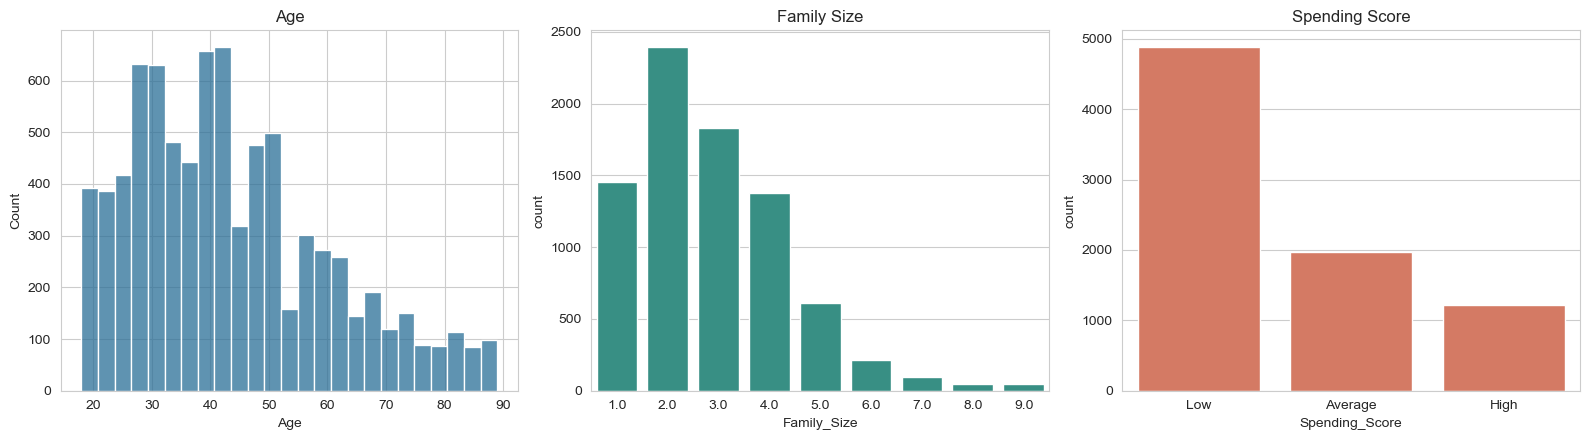

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(data["Age"], bins=25, ax=ax[0], color="#2a6f97"); ax[0].set_title("Age")
sns.countplot(x="Family_Size", data=data, ax=ax[1], color="#2a9d8f"); ax[1].set_title("Family Size")
sns.countplot(x="Spending_Score", data=data, order=["Low", "Average", "High"], ax=ax[2], color="#e76f51"); ax[2].set_title("Spending Score")
plt.tight_layout(); plt.show()

### Observations
- Customers are fairly mature: average age **43** (range 18–89). The age distribution is right-skewed with a long tail of older customers.
- **60%** of customers have a *Low* spending score, 24% *Average* and only **15%** *High*. High spenders are a small, valuable minority.
- Typical households have 2–4 people (median family size 3); work experience is very skewed (median 1 year, mean 2.4).
- *Not available:* average purchase value, purchase frequency and customer lifetime value, because there are no transactions (see the note at the top).

## 4. Feature Selection
The brief suggests 2–3 key behavioural features. Without purchase data I use **4 customer features** that describe life stage and spending level:

| Used for clustering | Why |
|---|---|
| `Age` | Strong driver of needs and budget |
| `Work_Experience` | Career stage and earning power |
| `Family_Size` | Household needs (single buyer vs. family) |
| `Spending_Score_num` | Closest available proxy for the *monetary* dimension of RFM |

**Left out of the clustering, but used to *describe* the clusters afterwards:** `Ever_Married`, `Graduated` and `Profession`. K-Means uses Euclidean distance, which suits numeric features but not nominal categories such as profession. Leaving them out keeps the distance meaningful. `Var_1` is an anonymous code with no interpretable meaning, and `Gender` showed little relation to spending.

**Limitation:** three of the four features are discrete (family size, spending score), which makes clusters less sharply separated than with continuous data. I report this honestly in the evaluation.

## 5. Standardise the Features
K-Means is distance-based, so features on larger scales (such as `Age`) would dominate. `StandardScaler` puts them on the same scale.

In [14]:
features = ["Age", "Work_Experience", "Family_Size", "Spending_Score_num"]
X_scaled = StandardScaler().fit_transform(data[features])
print(pd.DataFrame(X_scaled, columns=features).describe().loc[["mean", "std"]].round(2))

      Age  Work_Experience  Family_Size  Spending_Score_num
mean  0.0             -0.0         -0.0                 0.0
std   1.0              1.0          1.0                 1.0


## 6. Choose the Number of Clusters (Elbow Method + Silhouette)

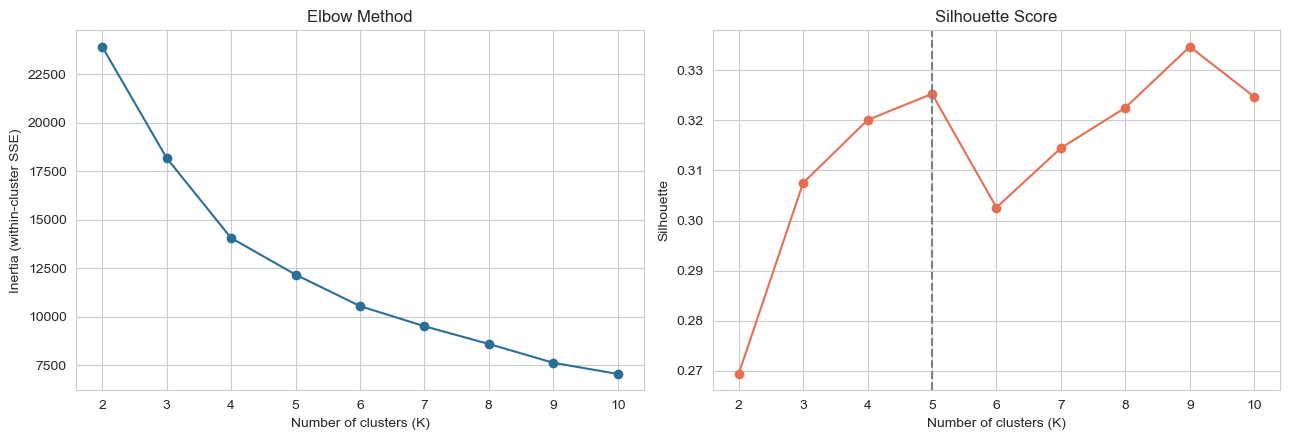

 K  Inertia  Silhouette
 2  23927.0       0.269
 3  18189.0       0.308
 4  14065.0       0.320
 5  12181.0       0.325
 6  10558.0       0.303
 7   9519.0       0.314
 8   8605.0       0.323
 9   7635.0       0.335
10   7059.0       0.325


In [15]:
k_range = range(2, 11)
inertia, silhouette = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_, sample_size=4000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(k_range, inertia, "o-", color="#2a6f97")
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("Number of clusters (K)"); ax[0].set_ylabel("Inertia (within-cluster SSE)")
ax[1].plot(k_range, silhouette, "o-", color="#e76f51")
ax[1].axvline(5, color="grey", linestyle="--")
ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("Number of clusters (K)"); ax[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"K": list(k_range), "Inertia": np.round(inertia), "Silhouette": np.round(silhouette, 3)}).to_string(index=False))

### Observations and decision
- **Elbow:** inertia drops steeply up to K ≈ 4–5, then flattens (K=4: 14,065; K=5: 12,181; K=6: 10,558). The elbow is gentle, not sharp.
- **Silhouette:** peaks at **K = 5 (0.325)**, slightly above K = 4 (0.320) and K = 6 (0.303).
- **Decision: K = 5.** Both methods point to 4–5, silhouette is highest at 5, and K = 5 gives five clearly different customer profiles that a marketing team could act on (Section 8).
- Note that silhouette scores around 0.3 mean the groups **overlap noticeably**; the clusters are useful summaries, not sharply separated natural groups.

## 7. Fit K-Means (K = 5)

In [16]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE)
raw_labels = kmeans.fit_predict(X_scaled)

# Number the clusters by average age so the numbering is the same on every run
order = pd.Series(data["Age"].values).groupby(raw_labels).mean().sort_values().index
mapping = {old: new for new, old in enumerate(order)}
data["Cluster"] = pd.Series(raw_labels, index=data.index).map(mapping)

# Names chosen after studying the profile table in Section 8
names = {0: "Young Starters", 1: "Experienced Professionals", 2: "Settled Families",
         3: "Frugal Small Households", 4: "Affluent Seniors"}
data["Segment"] = data["Cluster"].map(names)

print("Silhouette (K=5):", round(silhouette_score(X_scaled, raw_labels, sample_size=4000, random_state=RANDOM_STATE), 3))

# How stable are the clusters? Re-run with 4 other random starts and compare
others = [KMeans(5, n_init=10, random_state=s).fit_predict(X_scaled) for s in range(1, 5)]
print("Agreement with other seeds (ARI):", [round(adjusted_rand_score(raw_labels, o), 3) for o in others])

Silhouette (K=5): 0.325
Agreement with other seeds (ARI): [1.0, 0.999, 0.996, 1.0]


The clusters are **stable**: re-running with different random starts gives the same grouping (agreement scores of 1.00–1.00 on a 0–1 scale), so the segments are not an accident of one random initialisation.

## 8. Visualise the Clusters

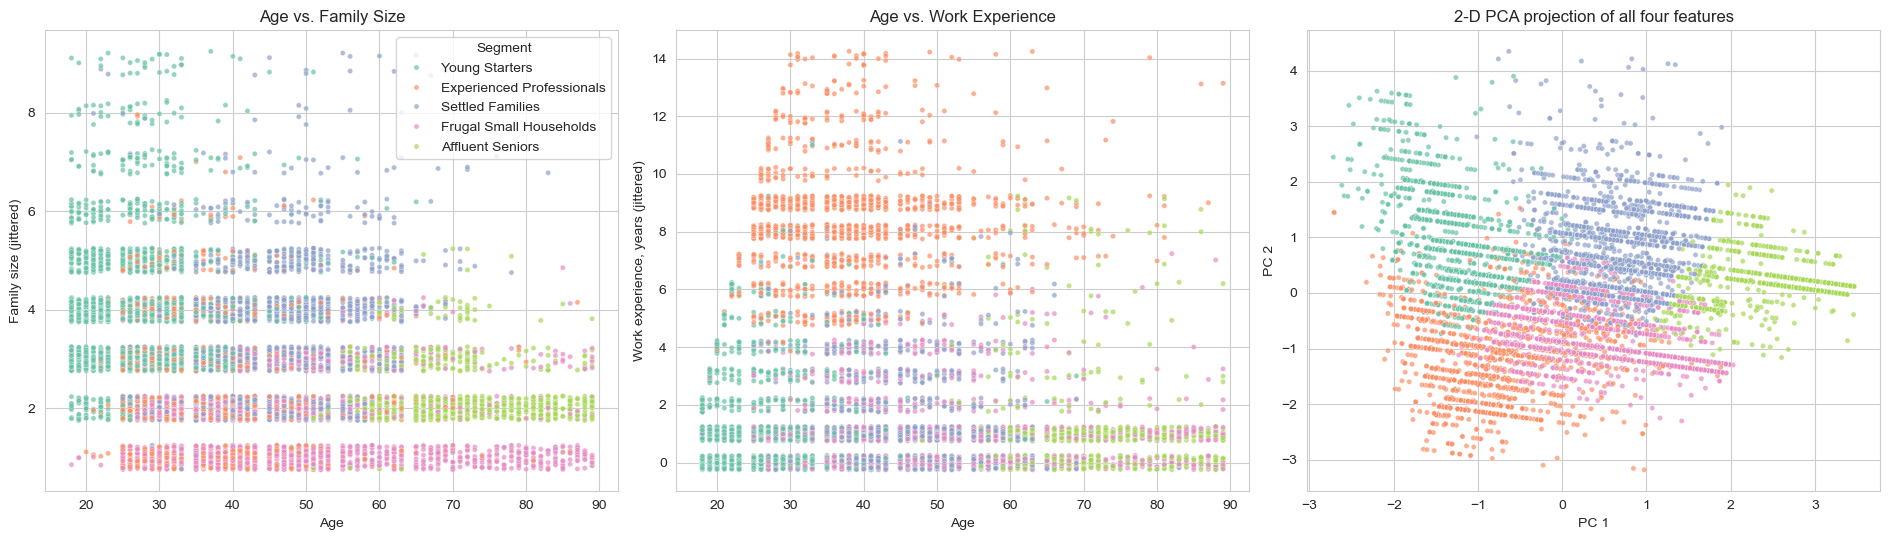

In [17]:
rng = np.random.default_rng(0)
jit = lambda s, a=0.25: s + rng.uniform(-a, a, len(s))   # jitter so discrete values don't overlap
palette = dict(zip(names.values(), sns.color_palette("Set2", 5)))
order_names = list(names.values())

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(x=data["Age"], y=jit(data["Family_Size"]), hue=data["Segment"], hue_order=order_names, palette=palette, s=14, alpha=.7, ax=ax[0])
ax[0].set_title("Age vs. Family Size"); ax[0].set_ylabel("Family size (jittered)")
sns.scatterplot(x=data["Age"], y=jit(data["Work_Experience"]), hue=data["Segment"], hue_order=order_names, palette=palette, s=14, alpha=.7, ax=ax[1], legend=False)
ax[1].set_title("Age vs. Work Experience"); ax[1].set_ylabel("Work experience, years (jittered)")
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=data["Segment"], hue_order=order_names, palette=palette, s=14, alpha=.7, ax=ax[2], legend=False)
ax[2].set_title("2-D PCA projection of all four features"); ax[2].set_xlabel("PC 1"); ax[2].set_ylabel("PC 2")
plt.tight_layout(); plt.show()

### Observations
- **Age vs. Family Size:** *Young Starters* sit at the left (age under 30) with large households; *Affluent Seniors* form a distinct group at the far right (age 60+); *Frugal Small Households* gather at family size 1–2.
- **Age vs. Work Experience:** *Experienced Professionals* are the group sitting high on the work-experience axis (about 8 years on average), which no other segment reaches.
- **PCA view:** the two main components capture 65% of the variation. Clusters appear as distinct bands, but with **overlapping edges**, which matches the moderate silhouette score.

## 9. Profile Each Cluster

In [18]:
profile = data.groupby("Segment").agg(
    Customers=("ID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Work_Exp=("Work_Experience", "mean"),
    Avg_Family_Size=("Family_Size", "mean"),
    Avg_Spending_Score=("Spending_Score_num", "mean"),
    Married_pct=("Ever_Married", lambda s: (s == "Yes").mean() * 100),
    Graduated_pct=("Graduated", lambda s: (s == "Yes").mean() * 100),
).loc[order_names]
profile["Share_pct"] = profile["Customers"] / len(data) * 100
display(profile.round(1))

spend_mix = (pd.crosstab(data["Segment"], data["Spending_Score"], normalize="index")[["Low", "Average", "High"]] * 100).loc[order_names]
print("Spending score mix within each segment (%):")
display(spend_mix.round(0))

print("Top two professions per segment:")
for seg in order_names:
    top = data.loc[data["Segment"] == seg, "Profession"].value_counts(normalize=True).head(2)
    print(f"  {seg}: " + ", ".join(f"{k} ({v*100:.0f}%)" for k, v in top.items()))

,Customers,Avg_Age,Avg_Work_Exp,Avg_Family_Size,Avg_Spending_Score,Married_pct,Graduated_pct,Share_pct
Segment,,,,,,,,
Young Starters,1925,27.4,1.2,4.1,0.0,13.1,33.0,23.9
Experienced Professionals,1428,38.1,8.4,2.4,0.4,51.1,71.0,17.7
Settled Families,1937,45.2,1.3,3.5,1.3,99.9,72.3,24.0
Frugal Small Households,1972,50.1,0.9,1.6,0.0,53.8,74.0,24.4
Affluent Seniors,806,70.8,1.1,2.3,1.8,100.0,66.6,10.0


Spending score mix within each segment (%):


Spending_Score,Low,Average,High
Segment,,,
Young Starters,99.0,1.0,0.0
Experienced Professionals,69.0,25.0,6.0
Settled Families,0.0,74.0,26.0
Frugal Small Households,100.0,0.0,0.0
Affluent Seniors,0.0,21.0,79.0


Top two professions per segment:
  Young Starters: Healthcare (50%), Doctor (12%)
  Experienced Professionals: Artist (35%), Entertainment (14%)
  Settled Families: Artist (45%), Executive (15%)
  Frugal Small Households: Artist (37%), Entertainment (14%)
  Affluent Seniors: Lawyer (40%), Artist (26%)


### Segment descriptions
| Segment | Size | Age | Work exp. | Family size | Married | Spending |
|---|---|---|---|---|---|---|
| **0 · Young Starters** | 24% | 27 | 1.2 yrs | 4.1 | 13% | 99% Low |
| **1 · Experienced Professionals** | 18% | 38 | **8.4 yrs** | 2.4 | 51% | mixed (69% Low, 25% Avg) |
| **2 · Settled Families** | 24% | 45 | 1.3 yrs | 3.5 | **100%** | 74% Avg, 26% High |
| **3 · Frugal Small Households** | 24% | 50 | 0.9 yrs | **1.6** | 54% | **100% Low** |
| **4 · Affluent Seniors** | 10% | **71** | 1.1 yrs | 2.3 | 100% | **79% High** |

- **Young Starters:** about 27 years old, mostly unmarried (87%), living in large households (≈4 people), and almost all low spenders (99%). Top professions: Healthcare (50%), Doctor (12%).
- **Experienced Professionals:** mid-career (≈38) with by far the most work experience (≈8 years); small households and mostly low-to-average spenders; the most "graduated" group (71%).
- **Settled Families:** all married, ≈3.5 people per household, solid **average** spenders (and 26% high); nobody in this group has a Low score.
- **Frugal Small Households:** small households (≈1.6 people) and **100% low spenders**, around age 50.
- **Affluent Seniors:** the oldest group (≈71), all married, and the **highest spenders** (79% High). Top professions: Lawyer (40%), Artist (26%). They are only 10% of customers.

## 10. Number of Customers per Cluster

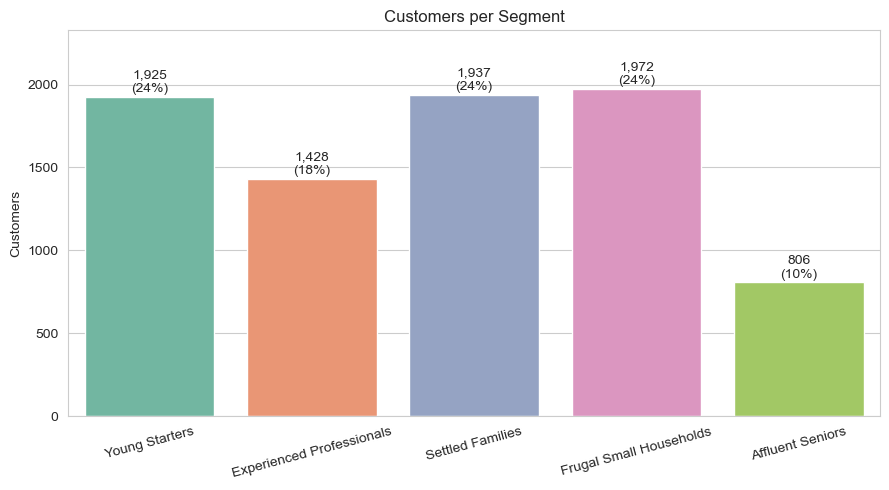

In [19]:
counts = data["Segment"].value_counts().reindex(order_names)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=counts.index, y=counts.values, palette=palette, order=order_names)
for i, v in enumerate(counts.values):
    ax.text(i, v + 30, f"{v:,}\n({v / len(data) * 100:.0f}%)", ha="center")
plt.title("Customers per Segment"); plt.xlabel(""); plt.ylabel("Customers")
plt.xticks(rotation=15); plt.ylim(0, counts.max() * 1.18)
plt.tight_layout(); plt.show()

### Observation
Segments are reasonably balanced: the biggest is *Frugal Small Households* (24% of customers) and the smallest is *Affluent Seniors* (10%). The small **Affluent Seniors** group is the most valuable per customer, so a small marketing effort aimed at them could have an outsized effect.

## 11. Do the Clusters Match the Company's Own Segments (A/B/C/D)?

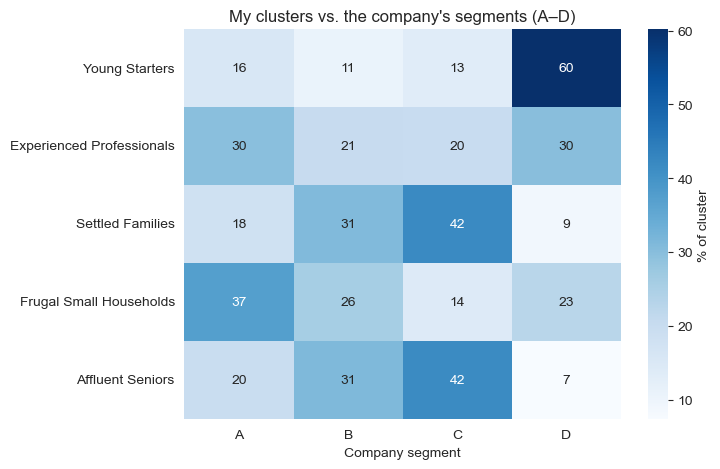

Adjusted Rand Index: 0.085 (0 = unrelated, 1 = identical)


In [21]:
comparison = pd.crosstab(data["Segment"], df["Segmentation"], normalize="index").loc[order_names] * 100
plt.figure(figsize=(7.5, 4.8))
sns.heatmap(comparison, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of cluster"})
plt.title("My clusters vs. the company's segments (A–D)"); plt.ylabel(""); plt.xlabel("Company segment")
plt.tight_layout(); plt.show()
print("Adjusted Rand Index:", round(adjusted_rand_score(df["Segmentation"], data["Cluster"]), 3), "(0 = unrelated, 1 = identical)")

### Observations
- The overall agreement is **very low** (adjusted Rand index **0.08**). My clusters are *not* a reproduction of the company's A–D labels.
- There is still a clear partial link: **60% of Young Starters are in company segment D**, while Settled Families and Affluent Seniors are mostly in segments B and C (73% and 73%). So the company's segment D appears to be "young customers", and B/C are "older, higher-spending".
- This is not a failure: the company's labels were produced with information I do not have, and K-Means groups by similarity of the four features, not by the company's definition. It does mean **my segments should be treated as a new, complementary view**, not a replacement for A–D.

## 12. Marketing Recommendations per Segment

These are **hypotheses based on demographics and spending score** (the dataset has no purchase history), so they should be tested with small pilot campaigns before large budgets are committed.

| Segment | Profile in one line | Recommended action |
|---|---|---|
| **Young Starters** (24%) | Under 30, unmarried, big households, low spending | Affordable entry-level products, flexible payment or financing, and digital/social-media campaigns. The goal is to build loyalty early so they upgrade as their income grows. |
| **Experienced Professionals** (18%) | Mid-career, ≈8 years of experience, mixed spending | Career-stage "upgrade" offers and mid-range premium options, loyalty or trade-in programmes. They have earning potential and are the best group to convert from Low to Average spenders. |
| **Settled Families** (24%) | Married, ≈3–4 people, solid average spenders | Family-oriented products and bundles, value packages, referral rewards and service plans. They are reliable, so retention matters more than acquisition. |
| **Frugal Small Households** (24%) | Small households, 100% low spenders | Price-led promotions and low-cost channels such as email. Keep spend per customer low, and test whether any can be upgraded; do not over-invest here. |
| **Affluent Seniors** (10%) | Oldest, high spenders, married | **Top retention priority**: premium offers, personal service, and phone or in-person contact. Small group, but highest value per customer, so lost customers here are costly. |

## 13. Conclusion

**What I did:** cleaned the data (including 163 impossible work-experience values), standardised four customer features, chose **K = 5** using the elbow method and silhouette score, and described five customer segments with a marketing action for each.

**Key findings**
- Customers fall into five meaningful groups, from **Young Starters** (low spend, large households) to **Affluent Seniors** (high spend, age 70).
- Only about 15% of customers are high spenders, and they are concentrated in the oldest segment, so **protecting that segment** is a priority.
- The clusters are **stable** (consistent across random starts).

**Limitations (please read)**
1. **No RFM.** The dataset has no transaction history, so Recency, Frequency, Monetary value, average purchase value and customer lifetime value could not be calculated. `Spending_Score` is only an ordinal proxy. A transaction dataset (for example UCI *Online Retail*) is needed for true RFM segmentation.
2. **Moderate cluster quality:** silhouette ≈ 0.33. The segments overlap, partly because three of the four features are discrete.
3. **Weak agreement with the company's A–D labels** (ARI 0.08); my clusters offer a different view.
4. Recommendations are hypotheses and need pilot testing.